# Module 10 — Reconnaissance d'entités nommées (NER) en profondeur

> **Objectif** : maîtriser l'étiquetage de séquences au-delà du « une softmax par token » du module 7. On compare les schémas d'étiquetage (BIO, BIOES), on construit de zéro un **CRF linéaire** (algorithme forward, forward-backward, Viterbi, gradient exact, tout vérifié numériquement) et on mesure ce qu'il apporte face à une classification token par token. On voit ensuite les approches **par spans** (entités imbriquées), les schémas d'évaluation stricts et partiels, et la version PyTorch / Hugging Face avec une couche CRF au-dessus d'un Transformer.

| | |
|---|---|
| **Durée estimée** | 3 h 30 |
| **Prérequis** | Modules 0 à 7 (surtout l'étiquetage de tokens du module 7, section 7) |
| **Librairies** | `numpy`, `matplotlib` ; `torch`, `transformers` (sections 8–9) |

**Plan**

1. La tâche et ses difficultés
2. Schémas d'étiquetage : BIO, IOB1, BIOES
3. Un corpus de NER avec ambiguïtés et noms inconnus
4. Baseline : classification indépendante de chaque token
5. Le CRF linéaire : modèle, fonction de partition, algorithme forward
6. Apprendre un CRF : forward-backward et gradient exact
7. Décoder : Viterbi ; comparaison avec la baseline
8. Au-delà des séquences : NER par spans et entités imbriquées
9. Évaluer : strict, partiel, par type ; analyse d'erreurs
10. Transformer + CRF en PyTorch / Hugging Face
11. Récapitulatif et exercices

In [1]:
import re
import zlib
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)


def logsumexp(a, axis=None, keepdims=False):
    m = np.max(a, axis=axis, keepdims=True)
    out = m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))
    return out if keepdims else np.squeeze(out, axis=axis)

## 1. La tâche et ses difficultés

La **reconnaissance d'entités nommées** consiste à repérer dans un texte des segments (*spans*) qui désignent des entités, et à leur attribuer un type : personne (PER), lieu (LOC), organisation (ORG), date (DATE)… En biomédecine : gènes, protéines, maladies, médicaments. Sur une séquence protéique : domaines, régions, motifs (module 9).

Ce qui rend la tâche difficile :

| Difficulté | Exemple |
|---|---|
| **Ambiguïté de type** | « Washington » : une personne ou une ville ? « Orange » : l'entreprise ou le fruit ? Le contexte décide. |
| **Frontières** | « l'Université de Montpellier » : où commence et où finit l'entité ? |
| **Entités multi-mots** | « Air France », « 7 novembre 1867 » : il faut savoir qu'un token **continue** une entité. |
| **Noms jamais vus** | une personne inconnue de l'entraînement : il faut généraliser à partir de la forme (majuscule) et du contexte (« M. », « née à »). |
| **Déséquilibre** | 80–90 % des tokens sont hors entité (`O`). L'exactitude par token est trompeuse (module 7). |
| **Imbrication** | « Université de **Paris** » : un LOC dans un ORG. Un étiquetage à une étiquette par token ne peut pas le représenter. |

Les sorties ont une **structure** : les étiquettes de tokens voisins sont fortement dépendantes. `I-PER` ne peut suivre que `B-PER` ou `I-PER`. Un modèle qui prédit chaque token indépendamment ignore cette structure ; le **CRF** la modélise explicitement.

## 2. Schémas d'étiquetage

Une liste d'entités (type, début, fin) se convertit en une étiquette par token. Les schémas courants :

| Schéma | Étiquettes | Règle |
|---|---|---|
| **IO** | `I-X`, `O` | ne sépare pas deux entités adjacentes de même type |
| **BIO** (IOB2) | `B-X`, `I-X`, `O` | `B-` à chaque début d'entité ; le plus utilisé |
| **IOB1** | `B-` seulement entre deux entités adjacentes de même type | historique (CoNLL-2003 original) |
| **BIOES** (BILOU) | `B-X`, `I-X`, `E-X`, `S-X`, `O` | marque aussi la **fin** (`E`) et les entités d'un seul token (`S`) |

BIOES donne au modèle un signal explicite sur les **deux** frontières, souvent un petit gain pour les modèles à transitions (CRF), au prix de $4T+1$ étiquettes au lieu de $2T+1$ ($T$ types).

In [2]:
def spans_to_tags(n_tokens, spans, scheme="BIO"):
    """spans: list of (type, start, end_exclusive)."""
    tags = ["O"] * n_tokens
    for typ, s, e in spans:
        if scheme == "BIO":
            tags[s] = f"B-{typ}"
            for i in range(s + 1, e):
                tags[i] = f"I-{typ}"
        elif scheme == "BIOES":
            if e - s == 1:
                tags[s] = f"S-{typ}"
            else:
                tags[s] = f"B-{typ}"
                for i in range(s + 1, e - 1):
                    tags[i] = f"I-{typ}"
                tags[e - 1] = f"E-{typ}"
        elif scheme == "IO":
            for i in range(s, e):
                tags[i] = f"I-{typ}"
    return tags


def tags_to_spans(tags):
    """Strict-ish decoding for BIO and BIOES (an I-/E- without a matching opening starts a new entity)."""
    spans, start, typ = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        prefix, _, ty = t.partition("-")
        closes = start is not None and (prefix in ("O", "B", "S") or ty != typ)
        if closes:
            spans.append((typ, start, i)); start, typ = None, None
        if prefix in ("B", "S") or (prefix in ("I", "E") and start is None):
            start, typ = i, ty
        if prefix in ("E", "S") and start is not None:
            spans.append((typ, start, i + 1)); start, typ = None, None
    return set(spans)


words = "Hier , Marie Curie et Pierre ont visité l' Institut Pasteur à Paris .".split()
spans = [("PER", 2, 4), ("PER", 5, 6), ("ORG", 9, 11), ("LOC", 12, 13)]
print(f"{'token':10s} {'IO':8s} {'BIO':8s} {'BIOES':8s}")
for w, a, b, c in zip(words, *(spans_to_tags(len(words), spans, s) for s in ["IO", "BIO", "BIOES"])):
    print(f"{w:10s} {a:8s} {b:8s} {c:8s}")
for s in ["BIO", "BIOES"]:
    assert tags_to_spans(spans_to_tags(len(words), spans, s)) == set(spans)
print("round trip OK for BIO and BIOES")

token      IO       BIO      BIOES   
Hier       O        O        O       
,          O        O        O       
Marie      I-PER    B-PER    B-PER   
Curie      I-PER    I-PER    E-PER   
et         O        O        O       
Pierre     I-PER    B-PER    S-PER   
ont        O        O        O       
visité     O        O        O       
l'         O        O        O       
Institut   I-ORG    B-ORG    B-ORG   
Pasteur    I-ORG    I-ORG    E-ORG   
à          O        O        O       
Paris      I-LOC    B-LOC    S-LOC   
.          O        O        O       
round trip OK for BIO and BIOES


## 3. Un corpus de NER avec ambiguïtés et noms inconnus

On génère des phrases françaises à partir de gabarits, avec des pièges volontaires :
- **ambiguïtés** : « Washington » (personne ou ville), « Orange » (entreprise, ou fruit en minuscule), « Jordan » (prénom) vs « Jordanie » (pays), « Paris » (ville) vs « Paris » (prénom, rare) ;
- **entités multi-mots** (« Air France », « Université de Montpellier », « 3 mars 2021 ») ;
- **noms réservés au test** : une partie des personnes, lieux et organisations n'apparaissent **jamais** à l'entraînement. Le modèle doit généraliser par la forme et le contexte.

> 📦 **Avec de vraies données** : WikiNER (français), CoNLL-2003 (anglais), ou en biomédical BC5CDR, NCBI-disease. Le code des sections 4 à 7 fonctionne sur n'importe quelle liste de `(mots, étiquettes)`.

In [3]:
FIRST = ["Marie", "Jean", "Sophie", "Ahmed", "Léa", "Lucas", "Fatou", "Hugo", "Inès", "Paul", "Chloé", "Yanis", "Jordan", "Camille"]
LAST = ["Curie", "Martin", "Diallo", "Bernard", "Nguyen", "Lefebvre", "Moreau", "Garcia", "Rousseau", "Fontaine"]
LOC = [["Paris"], ["Lyon"], ["Marseille"], ["Montpellier"], ["Toulouse"], ["New", "York"], ["Saint-Étienne"], ["Jordanie"],
       ["Washington"], ["Le", "Mans"], ["Bruxelles"], ["Dakar"], ["Rennes"], ["Nantes"]]
ORG = [["Orange"], ["Air", "France"], ["Sanofi"], ["Renault"], ["CNRS"], ["Institut", "Pasteur"], ["Université", "de", "Montpellier"],
       ["Société", "Générale"], ["Inserm"], ["La", "Poste"], ["Michelin"], ["Danone"]]
MONTHS = ["janvier", "février", "mars", "avril", "mai", "juin", "juillet", "septembre", "octobre", "novembre"]
# names held out from training: they only appear at test time
TEST_ONLY = {"FIRST": {"Fatou", "Yanis", "Camille"}, "LAST": {"Garcia", "Fontaine"},
             "LOC": {"Dakar", "Rennes", "Nantes"}, "ORG": {"Danone", "Michelin", "La Poste"}}


def pick(r, pool, kind, split):
    def name(x):
        return x if isinstance(x, str) else " ".join(x)
    allowed = [x for x in pool if (name(x) in TEST_ONLY[kind]) == (split == "test")] if split == "test" and r.random() < 0.6 \
        else [x for x in pool if name(x) not in TEST_ONLY[kind]]
    x = allowed[r.integers(len(allowed))]
    return [x] if isinstance(x, str) else list(x)


def make_sentence(r, split):
    per = pick(r, FIRST, "FIRST", split) + (pick(r, LAST, "LAST", split) if r.random() < 0.7 else [])
    if r.random() < 0.08:
        per = ["George", "Washington"]
    loc, org = pick(r, LOC, "LOC", split), pick(r, ORG, "ORG", split)
    date = [str(r.integers(1, 29)), MONTHS[r.integers(len(MONTHS))], str(r.integers(1950, 2025))]
    if r.random() < 0.3:
        date = date[:2]
    E = lambda toks, typ: (toks, typ)
    templates = [
        [E(per, "PER"), "travaille", "chez", E(org, "ORG"), "à", E(loc, "LOC"), "depuis", "le", E(date, "DATE"), "."],
        [E(org, "ORG"), "a", "ouvert", "un", "bureau", "à", E(loc, "LOC"), "."],
        ["Le", E(date, "DATE"), ",", E(per, "PER"), "a", "quitté", E(loc, "LOC"), "."],
        [E(per, "PER"), ",", "directrice", "de", E(org, "ORG"), ",", "est", "née", "à", E(loc, "LOC"), "."],
        ["Selon", E(org, "ORG"), ",", E(per, "PER"), "arrivera", "à", E(loc, "LOC"), "le", E(date, "DATE"), "."],
        ["Il", "a", "mangé", "une", "orange", "à", E(loc, "LOC"), "avec", E(per, "PER"), "."],
        ["M.", E(pick(r, LAST, "LAST", split), "PER"), "a", "rejoint", E(org, "ORG"), "."],
        ["La", "réunion", "à", E(loc, "LOC"), "a", "été", "reportée", "."],
        ["Les", "chercheurs", "de", E(org, "ORG"), "publient", "souvent", "."],
    ]
    tpl = templates[r.integers(len(templates))]
    words, spans = [], []
    for item in tpl:
        if isinstance(item, tuple):
            toks, typ = item
            spans.append((typ, len(words), len(words) + len(toks)))
            words += toks
        else:
            words.append(item)
    return words, spans_to_tags(len(words), spans, "BIO")


r = np.random.default_rng(0)
train = [make_sentence(r, "train") for _ in range(2500)]
test = [make_sentence(r, "test") for _ in range(800)]
TYPES = ["PER", "LOC", "ORG", "DATE"]
LABELS = ["O"] + [f"{p}-{t}" for t in TYPES for p in ("B", "I")]
L2I = {l: i for i, l in enumerate(LABELS)}
K = len(LABELS)
for w, t in train[:4]:
    print(" ".join(f"{x}/{y}" if y != "O" else x for x, y in zip(w, t)))
c = Counter(t for _, ts in train for t in ts)
print(f"\n{len(train)} train / {len(test)} test sentences | label distribution: {dict(c.most_common())}")

Les chercheurs de Orange/B-ORG publient souvent .
M. Moreau/B-PER a rejoint Université/B-ORG de/I-ORG Montpellier/I-ORG .
Orange/B-ORG a ouvert un bureau à Lyon/B-LOC .
Les chercheurs de Renault/B-ORG publient souvent .

2500 train / 800 test sentences | label distribution: {'O': 15593, 'B-LOC': 1965, 'B-PER': 1711, 'B-ORG': 1685, 'I-DATE': 1474, 'I-PER': 990, 'I-ORG': 955, 'B-DATE': 854, 'I-LOC': 361}


## 4. Baseline : classification indépendante de chaque token

On représente chaque token par des **caractéristiques creuses** classiques (le mot en minuscules, sa « forme » `Xxxx`, ses préfixes et suffixes, la présence d'une majuscule, ses voisins…), hachées dans un espace de dimension $D$ (l'*astuce du hachage* : pas de dictionnaire à maintenir). Les scores d'un token sont $e_t = W^\top \phi(x, t)\in\mathbb R^K$ : une ligne de $W$ par caractéristique active, sommées.

**Modèle indépendant** : $p(y_t\mid x) = \mathrm{softmax}(e_t)$, entraîné par entropie croisée token par token. C'est exactement ce que fait une tête `AutoModelForTokenClassification`, avec un Transformer à la place des caractéristiques manuelles.

In [4]:
D = 2 ** 14


def shape(w):
    s = re.sub("[A-ZÀ-Ý]", "X", w); s = re.sub("[a-zà-ÿ]", "x", s); s = re.sub("[0-9]", "d", s)
    return re.sub(r"(.)\1+", r"\1\1", s)                 # compress runs: Xxxxxx -> Xxx


def token_features(words, t):
    w = words[t]
    feats = ["bias", f"w={w.lower()}", f"shape={shape(w)}", f"pre3={w[:3].lower()}", f"suf3={w[-3:].lower()}",
             f"cap={w[:1].isupper()}", f"first={t == 0}", f"digit={w.isdigit()}"]
    for off in (-2, -1, 1, 2):
        j = t + off
        ww = words[j] if 0 <= j < len(words) else "<pad>"
        feats += [f"w[{off}]={ww.lower()}", f"shape[{off}]={shape(ww)}"]
    return [zlib.crc32(f.encode()) % D for f in feats]       # deterministic hashing trick


def featurize(data):
    return [([token_features(w, t) for t in range(len(w))], np.array([L2I[x] for x in tags])) for w, tags in data]


F_train, F_test = featurize(train), featurize(test)


def emissions(W, feats):
    return np.stack([W[f].sum(0) for f in feats])         # (T, K)


class Adam:
    def __init__(self, params, lr=0.05, b1=0.9, b2=0.999, eps=1e-8):
        self.p, self.lr, self.b1, self.b2, self.eps = params, lr, b1, b2, eps
        self.m = [np.zeros_like(x) for x in params]; self.v = [np.zeros_like(x) for x in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g * g
            p -= self.lr * (m / (1 - self.b1 ** self.t)) / (np.sqrt(v / (1 - self.b2 ** self.t)) + self.eps)


def softmax(z):
    z = z - z.max(-1, keepdims=True); e = np.exp(z); return e / e.sum(-1, keepdims=True)


def train_independent(data, epochs=4, lr=0.05, l2=1e-6, seed=0):
    r = np.random.default_rng(seed)
    W = np.zeros((D, K)); opt = Adam([W], lr=lr)
    for ep in range(epochs):
        for i in r.permutation(len(data)):
            feats, y = data[i]
            P = softmax(emissions(W, feats))
            dE = P.copy(); dE[np.arange(len(y)), y] -= 1          # softmax + CE: p - y (module 0)
            G = np.zeros_like(W)
            for t, f in enumerate(feats):
                np.add.at(G, f, dE[t])
            opt.step([G + l2 * W])
    return W

W_ind = train_independent(F_train)
print("independent model trained")

independent model trained


## 5. Le CRF linéaire

### 💡 Intuition

Au lieu de choisir chaque étiquette séparément, on attribue un score à **toute la séquence d'étiquettes** :
- un score d'**émission** $e_t(y_t)$ : « ce token ressemble-t-il à un `B-PER` ? » (le même que la baseline) ;
- un score de **transition** $A_{y_{t-1}, y_t}$ : « un `I-PER` après un `O` est-il plausible ? » (le CRF apprendra un score très négatif).

La meilleure séquence est celle qui maximise la somme des deux. Le modèle peut alors préférer un `B-ORG` peu probable localement si cela rend tout le reste cohérent.

### 📐 Le modèle

Pour une phrase $x$ de longueur $T$ et une séquence d'étiquettes $y = (y_1,\dots,y_T)$ :
$$
s(x, y) = \pi_{y_1} + \sum_{t=1}^{T} e_t(y_t) + \sum_{t=2}^{T} A_{y_{t-1},y_t} + \omega_{y_T}
$$
avec $\pi$ et $\omega$ des scores de début et de fin. Le CRF définit une distribution sur **toutes** les séquences :
$$
p(y\mid x) = \frac{\exp s(x, y)}{Z(x)},\qquad Z(x) = \sum_{y'\in\mathcal Y^T}\exp s(x, y')
$$

C'est une **softmax sur les $K^T$ séquences possibles** (module 0). La perte est la NLL : $\mathcal L = -s(x, y) + \log Z(x)$.

### 📐 L'algorithme forward : calculer $\log Z$ en $O(TK^2)$

$K^T$ séquences, c'est $9^{12}\approx 2{,}8\cdot10^{11}$ pour une phrase de 12 mots : impossible à énumérer. Mais le score se **décompose** sur des paires de positions voisines, ce qui permet la programmation dynamique. Soit $\alpha_t(k)$ le log de la somme des exponentielles des scores de tous les préfixes de longueur $t$ finissant par l'étiquette $k$ :
$$
\alpha_1(k) = \pi_k + e_1(k),\qquad
\alpha_t(k) = e_t(k) + \log\sum_{j}\exp\big(\alpha_{t-1}(j) + A_{jk}\big),\qquad
\log Z = \log\sum_k\exp\big(\alpha_T(k) + \omega_k\big)
$$
C'est l'algorithme de Viterbi (module 9) où l'on remplace $\max$ par $\log\sum\exp$ : un « max doux ». On travaille en **log** pour éviter les débordements (module 0).

In [5]:
def crf_score(E, y, A, start, end):
    return start[y[0]] + E[np.arange(len(y)), y].sum() + A[y[:-1], y[1:]].sum() + end[y[-1]]


def crf_forward(E, A, start):
    T, K_ = E.shape
    alpha = np.zeros((T, K_))
    alpha[0] = start + E[0]
    for t in range(1, T):
        alpha[t] = E[t] + logsumexp(alpha[t - 1][:, None] + A, axis=0)    # sum over previous label j
    return alpha


def crf_log_partition(E, A, start, end):
    return logsumexp(crf_forward(E, A, start)[-1] + end)


# Verification by brute-force enumeration on a tiny problem (T=4, K=3 -> 81 sequences)
from itertools import product
T_s, K_s = 4, 3
E_s, A_s = rng.normal(size=(T_s, K_s)), rng.normal(size=(K_s, K_s))
st_s, en_s = rng.normal(size=K_s), rng.normal(size=K_s)
brute = logsumexp(np.array([crf_score(E_s, np.array(y), A_s, st_s, en_s) for y in product(range(K_s), repeat=T_s)]))
print(f"log Z forward = {crf_log_partition(E_s, A_s, st_s, en_s):.10f} | brute force = {brute:.10f}")

log Z forward = 4.7367294108 | brute force = 4.7367294108


## 6. Apprendre un CRF : forward-backward et gradient exact

### 📐 Le gradient

$\mathcal L = -s(x,y) + \log Z(x)$. Le gradient de $\log Z$ par rapport à un score est l'**espérance** du terme correspondant sous le modèle (propriété générale des familles exponentielles) :
$$
\frac{\partial\log Z}{\partial e_t(k)} = p(y_t = k\mid x),\qquad
\frac{\partial\log Z}{\partial A_{jk}} = \sum_{t=2}^{T} p(y_{t-1} = j,\ y_t = k\mid x)
$$
D'où le gradient de la perte, encore une fois de la forme **« prédiction − vérité »** :
$$
\frac{\partial\mathcal L}{\partial e_t(k)} = p(y_t = k\mid x) - \mathbb 1[y_t = k],\qquad
\frac{\partial\mathcal L}{\partial A_{jk}} = \sum_t p(y_{t-1}=j, y_t=k\mid x) - \#\{t: y_{t-1}=j, y_t=k\}
$$
Comparé à la baseline, seule différence : les probabilités sont les **marginales du CRF**, qui tiennent compte des voisins, au lieu de softmax indépendantes.

### 📐 Les marginales : forward-backward

On calcule aussi les quantités « backward » $\beta_t(k)$ (log-somme sur tous les **suffixes** partant de $k$ en $t$) :
$$
\beta_T(k) = \omega_k,\qquad \beta_t(j) = \log\sum_k\exp\big(A_{jk} + e_{t+1}(k) + \beta_{t+1}(k)\big)
$$
puis
$$
p(y_t = k\mid x) = \exp\big(\alpha_t(k) + \beta_t(k) - \log Z\big),\qquad
p(y_{t-1}=j, y_t=k\mid x) = \exp\big(\alpha_{t-1}(j) + A_{jk} + e_t(k) + \beta_t(k) - \log Z\big)
$$

In [6]:
def crf_marginals(E, A, start, end):
    T, K_ = E.shape
    alpha = crf_forward(E, A, start)
    beta = np.zeros((T, K_)); beta[-1] = end
    for t in range(T - 2, -1, -1):
        beta[t] = logsumexp(A + (E[t + 1] + beta[t + 1])[None, :], axis=1)
    logZ = logsumexp(alpha[-1] + end)
    unary = np.exp(alpha + beta - logZ)                                              # (T, K)
    pair = np.exp(alpha[:-1, :, None] + A[None] + (E[1:] + beta[1:])[:, None, :] - logZ)   # (T-1, K, K)
    return logZ, unary, pair


def crf_nll_and_grads(E, y, A, start, end):
    logZ, unary, pair = crf_marginals(E, A, start, end)
    nll = logZ - crf_score(E, y, A, start, end)
    dE = unary.copy(); dE[np.arange(len(y)), y] -= 1
    dA = pair.sum(0); np.add.at(dA, (y[:-1], y[1:]), -1)
    dstart = unary[0].copy(); dstart[y[0]] -= 1
    dend = unary[-1].copy(); dend[y[-1]] -= 1
    return nll, dE, dA, dstart, dend


# Check: marginals sum to 1, and gradients match finite differences
y_s = np.array([0, 2, 2, 1])
nll, dE, dA, dst, den = crf_nll_and_grads(E_s, y_s, A_s, st_s, en_s)
_, unary, _ = crf_marginals(E_s, A_s, st_s, en_s)
print("marginals sum to 1:", np.allclose(unary.sum(1), 1))
h = 1e-6
num_dA = np.zeros_like(A_s)
for j in range(K_s):
    for k in range(K_s):
        Ap, Am = A_s.copy(), A_s.copy(); Ap[j, k] += h; Am[j, k] -= h
        num_dA[j, k] = (crf_nll_and_grads(E_s, y_s, Ap, st_s, en_s)[0] - crf_nll_and_grads(E_s, y_s, Am, st_s, en_s)[0]) / (2 * h)
print("max |dA analytic - numeric| =", np.abs(dA - num_dA).max())

marginals sum to 1: True
max |dA analytic - numeric| = 4.734739267320265e-10


Entraînement du CRF avec exactement les mêmes caractéristiques, le même optimiseur et le même nombre d'époques que la baseline : la **seule** différence est la structure.

In [7]:
def train_crf(data, epochs=4, lr=0.05, l2=1e-6, seed=0):
    r = np.random.default_rng(seed)
    W = np.zeros((D, K)); A = np.zeros((K, K)); start = np.zeros(K); end = np.zeros(K)
    opt = Adam([W, A, start, end], lr=lr)
    hist = []
    for ep in range(epochs):
        tot = 0.0
        for i in r.permutation(len(data)):
            feats, y = data[i]
            nll, dE, dA, dst, den = crf_nll_and_grads(emissions(W, feats), y, A, start, end)
            G = np.zeros_like(W)
            for t, f in enumerate(feats):
                np.add.at(G, f, dE[t])
            opt.step([G + l2 * W, dA, dst, den])
            tot += nll
        hist.append(tot / len(data))
        print(f"epoch {ep}: mean NLL per sentence {hist[-1]:.3f}")
    return W, A, start, end

W_crf, A_crf, start_crf, end_crf = train_crf(F_train)

epoch 0: mean NLL per sentence 0.087
epoch 1: mean NLL per sentence 0.000
epoch 2: mean NLL per sentence 0.000
epoch 3: mean NLL per sentence 0.000


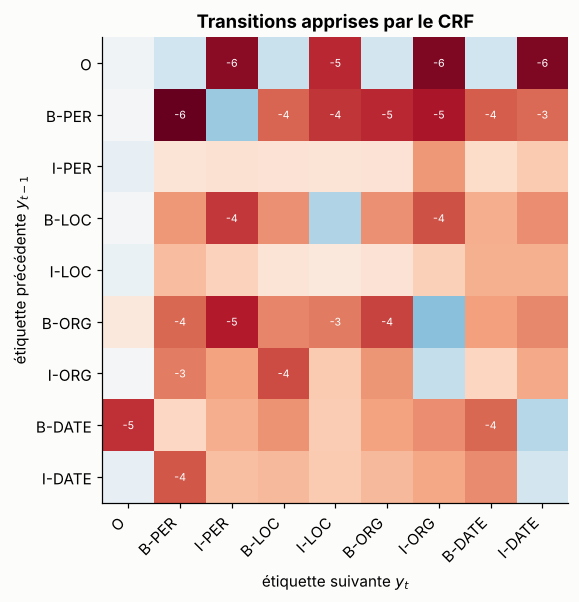

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
vmax = np.abs(A_crf).max()
ax.imshow(A_crf, cmap="RdBu", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(K)); ax.set_xticklabels(LABELS, rotation=45, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(LABELS)
ax.set_xlabel("étiquette suivante $y_t$"); ax.set_ylabel("étiquette précédente $y_{t-1}$"); ax.grid(False)
for (j, k), v in np.ndenumerate(A_crf):
    if abs(v) > 0.5 * vmax:
        ax.text(k, j, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
ax.set_title("Transitions apprises par le CRF")
plt.show()

Le CRF a appris **seul** la grammaire du schéma BIO : les transitions interdites (`O → I-X`, `B-PER → I-ORG`…) ont des scores très négatifs (rouge), tandis que `B-X → I-X` est favorisée (bleu). Il a aussi appris des régularités du corpus, comme la rareté de deux personnes adjacentes (`B-PER → B-PER`). Personne ne lui a donné ces règles.

## 7. Décoder : Viterbi, et comparaison avec la baseline

À l'inférence, on cherche la séquence la plus probable $\hat y = \arg\max_y s(x, y)$ : l'algorithme forward avec $\max$ au lieu de $\log\sum\exp$, plus des pointeurs arrière (module 9).

In [9]:
def crf_viterbi(E, A, start, end):
    T, K_ = E.shape
    delta = start + E[0]; back = np.zeros((T, K_), dtype=int)
    for t in range(1, T):
        cand = delta[:, None] + A                      # (prev, next)
        back[t] = cand.argmax(0)
        delta = cand.max(0) + E[t]
    path = [int(np.argmax(delta + end))]
    for t in range(T - 1, 0, -1):
        path.append(back[t, path[-1]])
    return np.array(path[::-1])


def is_valid_bio(tags):
    prev = "O"
    for t in tags:
        if t.startswith("I-") and prev[2:] != t[2:]:
            return False
        prev = t
    return True


def evaluate(pred_fn, data_feats, data_raw):
    tp = fp = fn = 0; invalid = 0; per_type = {t: [0, 0, 0] for t in TYPES}
    oov_hits, oov_total = 0, 0
    test_only_words = set().union(*TEST_ONLY.values())
    for (feats, y), (words, tags) in zip(data_feats, data_raw):
        pred = [LABELS[k] for k in pred_fn(feats)]
        invalid += not is_valid_bio(pred)
        T_, P_ = tags_to_spans(tags), tags_to_spans(pred)
        tp += len(T_ & P_); fp += len(P_ - T_); fn += len(T_ - P_)
        for typ, s, e in T_:
            per_type[typ][2] += 1
            if (typ, s, e) in P_:
                per_type[typ][0] += 1
            if " ".join(words[s:e]) in test_only_words or any(w in test_only_words for w in words[s:e]):
                oov_total += 1; oov_hits += (typ, s, e) in P_
        for typ, s, e in P_:
            per_type[typ][1] += 1
    p, r_ = tp / max(1, tp + fp), tp / max(1, tp + fn)
    f1_type = {t: 2 * v[0] / max(1, v[1] + v[2]) for t, v in per_type.items()}
    return {"P": p, "R": r_, "F1": 2 * p * r_ / max(1e-12, p + r_), "invalid": invalid / len(data_raw),
            "F1_type": f1_type, "recall_unseen_names": oov_hits / max(1, oov_total)}

res_ind = evaluate(lambda f: emissions(W_ind, f).argmax(1), F_test, test)
res_crf = evaluate(lambda f: crf_viterbi(emissions(W_crf, f), A_crf, start_crf, end_crf), F_test, test)
for name, res in [("indépendant (softmax)", res_ind), ("CRF + Viterbi", res_crf)]:
    print(f"{name:22s} entity P {res['P']:.3f} R {res['R']:.3f} F1 {res['F1']:.3f} | invalid BIO sequences {res['invalid']:.1%} "
          f"| recall on unseen names {res['recall_unseen_names']:.3f}")
    print(" " * 24 + "F1 by type: " + ", ".join(f"{t} {v:.3f}" for t, v in res["F1_type"].items()))

indépendant (softmax)  entity P 0.948 R 0.948 F1 0.948 | invalid BIO sequences 4.5% | recall on unseen names 0.906
                        F1 by type: PER 0.978, LOC 0.986, ORG 0.841, DATE 1.000
CRF + Viterbi          entity P 0.962 R 0.962 F1 0.962 | invalid BIO sequences 0.0% | recall on unseen names 0.931
                        F1 by type: PER 0.968, LOC 0.986, ORG 0.905, DATE 1.000



Selon La Poste , Paul Bernard arrivera à Nantes le 20 octobre .
  gold   O       B-ORG   I-ORG   O       B-PER   I-PER   O       O       B-LOC   O       B-DATE  I-DATE  O      
  indep  O       O       I-ORG   O       B-PER   I-PER   O       O       B-LOC   O       B-DATE  I-DATE  O      
  crf    O       O       B-PER   O       B-PER   I-PER   O       O       B-LOC   O       B-DATE  I-DATE  O      

Les chercheurs de La Poste publient souvent .
  gold   O       O       O       B-ORG   I-ORG   O       O       O      
  indep  O       O       O       O       I-ORG   O       O       O      
  crf    O       O       O       B-ORG   I-ORG   O       O       O      

Jordan , directrice de La Poste , est née à Nantes .
  gold   B-PER   O       O       O       B-ORG   I-ORG   O       O       O       O       B-LOC   O      
  indep  B-PER   O       O       O       O       I-ORG   O       O       O       O       B-LOC   O      
  crf    B-PER   O       O       O       O       B-PER   O       O

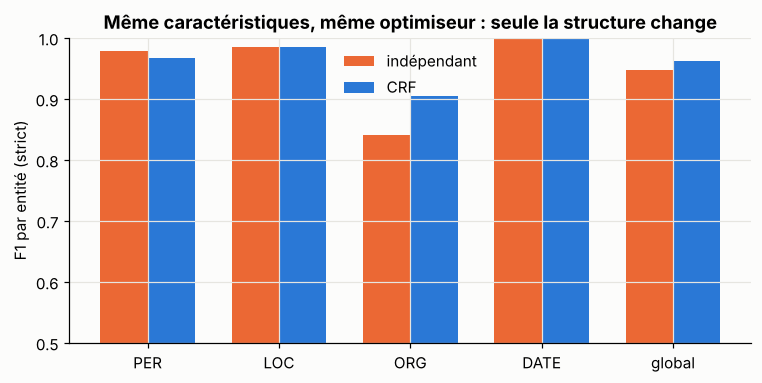

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(TYPES) + 1)
for k, (name, res, c) in enumerate([("indépendant", res_ind, PALETTE[1]), ("CRF", res_crf, PALETTE[0])]):
    vals = [res["F1_type"][t] for t in TYPES] + [res["F1"]]
    ax.bar(x + (k - 0.5) * 0.36, vals, 0.36, color=c, label=name)
ax.set_xticks(x); ax.set_xticklabels(TYPES + ["global"]); ax.set_ylim(0.5, 1.0); ax.set_ylabel("F1 par entité (strict)")
ax.set_title("Même caractéristiques, même optimiseur : seule la structure change"); ax.legend()
plt.show()

# Look at concrete disagreements
shown = 0
for (feats, y), (words, tags) in zip(F_test, test):
    p_ind = [LABELS[k] for k in emissions(W_ind, feats).argmax(1)]
    p_crf = [LABELS[k] for k in crf_viterbi(emissions(W_crf, feats), A_crf, start_crf, end_crf)]
    if p_ind != p_crf and shown < 4:
        shown += 1
        print("\n" + " ".join(words))
        for lab, seq in [("gold", tags), ("indep", p_ind), ("crf", p_crf)]:
            print(f"  {lab:6s}", " ".join(f"{t:7s}" for t in seq))

**Lecture critique** :
- La baseline produit des séquences BIO **invalides** (un `I-` orphelin), que le décodage doit « réparer » au petit bonheur ; le CRF n'en produit jamais (les transitions interdites ont un score très négatif).
- Le gain se concentre sur les **entités multi-mots** et sur les noms jamais vus (ici surtout les ORG comme « La Poste », dont le premier mot est ambigu) : décider qu'un token **ouvre** ou **continue** une entité dépend de l'étiquette voisine, exactement ce que modélisent les transitions.
- Le CRF n'est pas magique : lis les désaccords affichés. Il lui arrive de produire une séquence **valide mais fausse** (un mauvais type pour toute l'entité), là où la baseline produisait une séquence invalide. Une sortie bien formée n'est pas une sortie juste.
- La perte d'entraînement tombe presque à zéro dès la 2e époque : les gabarits sont faciles à mémoriser. La vraie difficulté est au test, sur les noms jamais vus : c'est ce que mesure la dernière colonne.
- Avec un encodeur contextuel puissant (BiLSTM, Transformer), chaque émission « voit » déjà les voisins, et le gain du CRF **diminue** : souvent +0,1 à +1 point de F1 sur CoNLL avec BERT, parfois rien. Il reste utile quand les données sont **rares**, quand les contraintes structurelles sont **fortes** (ordre imposé des régions d'une séquence biologique, module 9), ou pour **garantir** des sorties valides.

## 8. Au-delà des séquences : NER par spans et entités imbriquées

Un étiquetage BIO attribue **une** étiquette par token : il ne peut pas représenter « [Université de [Paris]LOC]ORG ». Les entités imbriquées sont fréquentes en biomédecine (« [récepteur [IL-2]PROT]PROT ») et dans les annotations hiérarchiques (une région contenant un motif).

### 📐 L'approche par spans

On énumère **tous les segments** $(i, j)$ de longueur $\le L_{\max}$ et on classe chacun dans $\{\text{non-entité}\}\cup\text{types}$ :
$$
h_{ij} = \big[\,h_i;\ h_j;\ \tfrac{1}{j-i+1}\textstyle\sum_{t=i}^{j}h_t;\ w_{\,j-i+1}\,\big],\qquad p(\text{type}\mid i,j) = \mathrm{softmax}(\mathrm{MLP}(h_{ij}))
$$
où $h_t$ sont les vecteurs contextuels (Transformer), et $w_\ell$ un embedding de **longueur** appris. Nombre de candidats : $O(T\cdot L_{\max})$.

- ✅ entités imbriquées et chevauchantes ; représentation explicite de tout le segment ;
- ❌ énormément de candidats négatifs (déséquilibre extrême) → sous-échantillonnage des négatifs ; il faut ensuite **résoudre les conflits** (non-maximum suppression : garder les spans les plus probables, refuser les chevauchements partiels non imbriqués).

In [11]:
words_n = "Les chercheurs de l' Université de Paris travaillent avec Air France .".split()
gold_nested = {("ORG", 4, 7), ("LOC", 6, 7), ("ORG", 9, 11)}
L_max = 4
candidates = [(i, j) for i in range(len(words_n)) for j in range(i + 1, min(len(words_n), i + L_max) + 1)]
print(f"{len(words_n)} tokens -> {len(candidates)} candidate spans (L_max={L_max}); {len(gold_nested)} are entities")
for typ, s, e in sorted(gold_nested, key=lambda x: x[1]):
    print(f"  {typ}: {' '.join(words_n[s:e])}  [{s}, {e})")
print("BIO can encode at most one label per token -> 'Paris' cannot be both inside ORG and its own LOC.")

12 tokens -> 42 candidate spans (L_max=4); 3 are entities
  ORG: Université de Paris  [4, 7)
  LOC: Paris  [6, 7)
  ORG: Air France  [9, 11)
BIO can encode at most one label per token -> 'Paris' cannot be both inside ORG and its own LOC.


Autres familles : **parsing en hypergraphe**, **seq2seq génératif** (le modèle écrit la liste des entités, comme un LLM), et **NER par question-réponse** (« Quelles sont les organisations dans ce texte ? »), pratique pour ajouter de nouveaux types sans réentraîner.

## 9. Évaluer : strict, partiel, par type

Le F1 « strict » (module 7) ne compte une entité juste que si **type et frontières** sont exacts. Le schéma d'évaluation de SemEval-2013 (tâche 9.1), repris par la librairie `nervaluate`, distingue cinq cas pour chaque paire (vérité, prédiction) :

| Cas | Frontières | Type | Exemple (vérité : « Air France »/ORG) |
|---|---|---|---|
| **correct** | exactes | juste | « Air France »/ORG |
| **incorrect** | exactes | faux | « Air France »/LOC |
| **partiel** | chevauchement | (ignoré ou exigé selon le mode) | « France »/ORG |
| **manquant** | aucune prédiction ne chevauche | | |
| **parasite** | prédiction sans vérité chevauchante | | |

et quatre modes : *strict* (frontières et type exacts), *exact* (frontières exactes, type ignoré), *partial* (chevauchement accepté, compté pour moitié), *type* (type juste et chevauchement). Rapporter plusieurs modes **localise** l'erreur : un modèle bon en *type* mais mauvais en *strict* a un problème de **frontières**, pas de typage.

In [12]:
def semeval_counts(gold, pred):
    """gold, pred: sets of (type, start, end). Returns counts per category (greedy matching)."""
    counts = Counter()
    matched_pred = set()
    for g in sorted(gold, key=lambda x: x[1]):
        overl = [p for p in pred if p[1] < g[2] and g[1] < p[2]]
        if not overl:
            counts["manquant"] += 1; continue
        p = max(overl, key=lambda q: min(q[2], g[2]) - max(q[1], g[1]))
        matched_pred.add(p)
        same_bounds, same_type = (p[1], p[2]) == (g[1], g[2]), p[0] == g[0]
        counts["correct" if same_bounds and same_type else "incorrect" if same_bounds else "partiel"] += 1
    counts["parasite"] = len(pred - matched_pred)
    return counts

def mode_scores(c):
    possible = c["correct"] + c["incorrect"] + c["partiel"] + c["manquant"]
    actual = c["correct"] + c["incorrect"] + c["partiel"] + c["parasite"]
    out = {}
    for mode, credit in [("strict", c["correct"]), ("partial", c["correct"] + 0.5 * c["partiel"])]:
        p, r_ = credit / max(1, actual), credit / max(1, possible)
        out[mode] = 2 * p * r_ / max(1e-12, p + r_)
    return out

for name, fn in [("indépendant", lambda f: emissions(W_ind, f).argmax(1)),
                 ("CRF", lambda f: crf_viterbi(emissions(W_crf, f), A_crf, start_crf, end_crf))]:
    total = Counter()
    for (feats, y), (words, tags) in zip(F_test, test):
        total += semeval_counts(tags_to_spans(tags), tags_to_spans([LABELS[k] for k in fn(feats)]))
    print(f"{name:12s} {dict(total)} -> F1 {mode_scores(total)}")

indépendant  {'correct': 1825, 'partiel': 100} -> F1 {'strict': 0.948051948051948, 'partial': 0.974025974025974}
CRF          {'correct': 1852, 'partiel': 73} -> F1 {'strict': 0.9620779220779221, 'partial': 0.981038961038961}


**Pour un vrai article**, rapporte : F1 strict micro et macro (par type), le mode partiel ou une tolérance de frontière, la performance sur les **noms jamais vus** à l'entraînement (c'est la vraie mesure de généralisation, cf. module 8 sur la fuite), et des intervalles bootstrap au niveau des **phrases** (rééchantillonner les phrases, pas les entités, car les entités d'une même phrase sont corrélées).

## 10. Transformer + CRF en PyTorch / Hugging Face

Une couche CRF au-dessus des émissions d'un Transformer. Les algorithmes forward et Viterbi sont **vectorisés sur le batch**, avec un masque pour les longueurs variables. Les étiquettes `-100` (sous-mots non initiaux, module 7) posent un problème : le CRF a besoin d'une séquence **continue** d'étiquettes. Solution standard : n'appliquer le CRF qu'aux **premiers sous-mots** de chaque mot (on les rassemble en une séquence compacte avant le CRF).

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer


class CRF(nn.Module):
    """Linear-chain CRF over (B, T, K) emissions with a (B, T) boolean mask (True = real position, left-aligned)."""

    def __init__(self, num_tags):
        super().__init__()
        self.trans = nn.Parameter(torch.zeros(num_tags, num_tags))     # trans[i, j] = score(i -> j)
        self.start = nn.Parameter(torch.zeros(num_tags))
        self.end = nn.Parameter(torch.zeros(num_tags))

    def _score(self, em, tags, mask):
        B, T, K = em.shape
        ar = torch.arange(B, device=em.device)
        score = self.start[tags[:, 0]] + em[ar, 0, tags[:, 0]]
        for t in range(1, T):
            step = self.trans[tags[:, t - 1], tags[:, t]] + em[ar, t, tags[:, t]]
            score = score + step * mask[:, t]
        last = tags[ar, mask.sum(1) - 1]
        return score + self.end[last]

    def _log_partition(self, em, mask):
        alpha = self.start + em[:, 0]                                         # (B, K)
        for t in range(1, em.shape[1]):
            nxt = torch.logsumexp(alpha.unsqueeze(2) + self.trans + em[:, t].unsqueeze(1), dim=1)   # (B, K)
            alpha = torch.where(mask[:, t].unsqueeze(1), nxt, alpha)        # padded steps keep alpha unchanged
        return torch.logsumexp(alpha + self.end, dim=1)

    def nll(self, em, tags, mask):
        return (self._log_partition(em, mask) - self._score(em, tags, mask)).mean()

    @torch.no_grad()
    def decode(self, em, mask):
        B, T, K = em.shape
        delta = self.start + em[:, 0]; backs = []
        for t in range(1, T):
            cand = delta.unsqueeze(2) + self.trans                            # (B, prev, next)
            best, idx = cand.max(dim=1)
            delta = torch.where(mask[:, t].unsqueeze(1), best + em[:, t], delta)
            backs.append(torch.where(mask[:, t].unsqueeze(1), idx, torch.arange(K, device=em.device).expand(B, K)))
        delta = delta + self.end
        paths = []
        for b in range(B):
            L = int(mask[b].sum())
            k = int(delta[b].argmax())
            path = [k]
            for t in range(L - 1, 0, -1):
                k = int(backs[t - 1][b, k]); path.append(k)
            paths.append(path[::-1])
        return paths


class TransformerCRFTagger(nn.Module):
    def __init__(self, backbone, num_tags, dropout=0.1):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(backbone)
        self.drop = nn.Dropout(dropout)
        self.emit = nn.Linear(self.encoder.config.hidden_size, num_tags)
        self.crf = CRF(num_tags)

    def word_emissions(self, input_ids, attention_mask, first_subword_index, word_mask):
        """first_subword_index: (B, W) position of each word's first sub-word; word_mask: (B, W) bool."""
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state   # (B, T_sub, d)
        h_words = torch.gather(h, 1, first_subword_index.unsqueeze(-1).expand(-1, -1, h.size(-1)))  # (B, W, d)
        return self.emit(self.drop(h_words))

    def forward(self, input_ids, attention_mask, first_subword_index, word_mask, word_labels=None):
        em = self.word_emissions(input_ids, attention_mask, first_subword_index, word_mask)
        if word_labels is not None:
            return self.crf.nll(em, word_labels.clamp(min=0), word_mask)
        return self.crf.decode(em, word_mask)


def collate_words(batch_words, batch_labels, tok, label2id, max_len=256):
    enc = tok(batch_words, is_split_into_words=True, truncation=True, max_length=max_len, padding=True, return_tensors="pt")
    W_max = max(len(w) for w in batch_words)
    first_idx = torch.zeros(len(batch_words), W_max, dtype=torch.long)
    word_mask = torch.zeros(len(batch_words), W_max, dtype=torch.bool)
    labels = torch.full((len(batch_words), W_max), -100, dtype=torch.long)
    for b in range(len(batch_words)):
        seen = set()
        for pos, wid in enumerate(enc.word_ids(b)):
            if wid is not None and wid not in seen:
                seen.add(wid); first_idx[b, wid] = pos; word_mask[b, wid] = True
                labels[b, wid] = label2id[batch_labels[b][wid]]
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
            "first_subword_index": first_idx, "word_mask": word_mask, "word_labels": labels}


tok = AutoTokenizer.from_pretrained("camembert-base")
model = TransformerCRFTagger("camembert-base", num_tags=K)
batch = collate_words([w for w, _ in train[:8]], [t for _, t in train[:8]], tok, L2I)
loss = model(**batch)
print("CRF NLL on a batch:", loss.item())
# Optimizer tip: give the CRF parameters (and the emission layer) a much larger lr than the encoder, e.g. 1e-3 vs 3e-5.
opt = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": 3e-5},
                         {"params": list(model.emit.parameters()) + list(model.crf.parameters()), "lr": 1e-3}], weight_decay=0.01)

> ⚠️ **Piège fréquent** : avec un masque contenant des « trous » (un `-100` au milieu de la séquence), le CRF ci-dessus serait faux, car il suppose les positions valides **contiguës à gauche**. C'est pour cela qu'on recompacte au niveau des mots avec `first_subword_index`. La librairie `pytorch-crf` (`from torchcrf import CRF`) impose la même contrainte (le premier pas de temps doit être valide).

**Test unitaire indispensable** : comparer `_log_partition` à une énumération brute sur une phrase de 4 tokens et 3 étiquettes, comme en section 5. Un CRF buggé apprend souvent « quelque chose » et le bug passe inaperçu.

## 11. Récapitulatif

| Notion | À retenir |
|---|---|
| Schémas | BIO (standard), BIOES (frontières explicites) ; conversions spans ↔ étiquettes |
| Baseline | une softmax par token ; séquences invalides possibles |
| CRF | $s(x,y) = \sum e_t(y_t) + \sum A_{y_{t-1}y_t}$ ; $p(y\mid x) = e^{s}/Z$ |
| Forward | $\log Z$ en $O(TK^2)$, log-sum-exp ; vérifier par énumération |
| Gradient | marginales − comptes observés (forward-backward) |
| Viterbi | max au lieu de logsumexp + pointeurs arrière |
| Gains du CRF | frontières, cohérence ; diminue avec un encodeur contextuel fort |
| Spans | entités imbriquées ; $O(TL)$ candidats ; résolution des conflits |
| Évaluation | strict / exact / partiel / type ; noms jamais vus ; bootstrap par phrase |
| HF + CRF | CRF sur les premiers sous-mots ; lr séparé pour la tête et le CRF |

### 🏋️ Exercices

1. **BIOES.** Réentraîne baseline et CRF avec le schéma BIOES. Le gain du CRF augmente-t-il ? Pourquoi les entités d'un seul token (`S-`) aident-elles ?
2. **Transitions contraintes.** Au lieu d'apprendre $A$, fixe à $-\infty$ les transitions interdites du BIO et apprends les autres. Compare la vitesse de convergence et le F1, surtout avec 200 phrases d'entraînement seulement.
3. **Marginales et confiance.** Utilise les marginales du CRF pour donner une **confiance par entité** (par exemple le produit des marginales de ses tokens). Trace un diagramme de fiabilité (module 8). Les entités sur des noms jamais vus sont-elles moins confiantes ?
4. **Semi-Markov.** Transforme le CRF en semi-CRF : chaque état est un **segment** (type, longueur ≤ L) avec un score de segment. Écris l'algorithme forward correspondant. C'est l'outil naturel pour des régions de longueur contrainte (module 9).
5. **Bug volontaire.** Dans `crf_marginals`, oublie `- logZ` dans `pair`. Le test de gradient le détecte-t-il ? Et l'entraînement ?

<details><summary>Indications</summary>

1. BIOES donne un signal explicite de fin d'entité ; le CRF peut alors apprendre des transitions plus informatives (`E-X → O`, `E-X → B-Y`).
2. Les contraintes dures reviennent à injecter une connaissance a priori ; leur avantage est maximal quand les données sont rares.
4. $\alpha(j) = \log\sum_{\ell=1}^{L}\sum_{y}\exp\big(\alpha(j-\ell, y') + A_{y'y} + \text{seg}(j-\ell, j, y)\big)$ : on somme sur la longueur du dernier segment.
5. Le test de gradient échoue immédiatement (les marginales jointes ne somment plus à 1). L'entraînement, lui, peut sembler « marcher », d'où l'importance des tests numériques.
</details>

**➡️ Module suivant : l'apprentissage contrastif** (InfoNCE, SimCLR et SimCSE, rôle de la température, alignement et uniformité, négatifs difficiles, embeddings de phrases et de séquences).